# Comparison of some methods of contraction

Import

In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import config
import general
import contraction
import constantes
import profiles

import pandas as pd

/Users/baptistesevilla/Documents/Ecole/Dark matter/profiles.py:292: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integrand, 0.0, np.inf, limit=constantes.ABEL_LIMIT, epsrel=epsrel, epsabs= constantes.ABEL_EPSABS)


Params for the plots

In [2]:
plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

XLIM = (1e-4, 3)
YLIM = (1e-6, 1e2)
FIGSIZE = (10,10)

Creation of the halo

In [3]:
halo = general.contract_halo()

r_n = halo['r'] / halo['r_vir']
rf_n = halo['r_f'] / halo['r_vir']

dm = halo['dm_profile']
bar = halo['baryon_profile']
cnt = halo['contraction']
r_s = halo['r_s']
r_vir = halo['r_vir']

rho_baryons = halo['rho_stars'] + halo['rho_gas']

Visualization of a single contraction

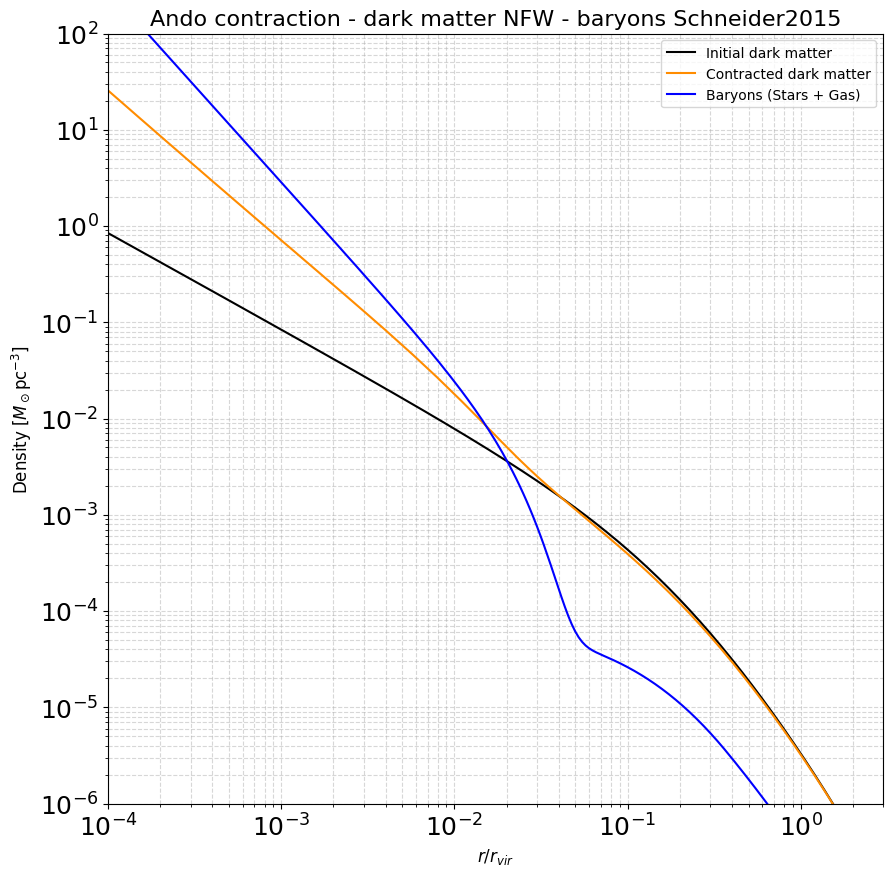

In [4]:
plt.figure(figsize=FIGSIZE)
plt.loglog(r_n, halo['rho_dm_initial'] , label=f'Initial dark matter', color='black')
plt.loglog(rf_n, halo['rho_dm_contracted'] , label=f'Contracted dark matter', color='darkorange')
plt.loglog(r_n, rho_baryons , label=f'Baryons (Stars + Gas)', color='blue')
plt.xlim(XLIM)
plt.ylim(YLIM)
plt.title(f"{cnt.capitalize()} contraction - dark matter {dm} - baryons {bar}", fontsize=16)
plt.xlabel(r'$r / r_{vir}$', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()

Params to have the explicit Blumenthal's method 

In [5]:
config.CONTRACTION = 'Blumenthal'
Blumenthal = general.contract_halo()
print (Blumenthal['contraction'])

r_n_blumenthal = Blumenthal['r'] / Blumenthal['r_vir']
rf_n_blumenthal = Blumenthal['r_f'] / Blumenthal['r_vir']

dm_blumenthal = Blumenthal['dm_profile']
bar_blumenthal = Blumenthal['baryon_profile']
cnt_blumenthal = Blumenthal['contraction']


Blumenthal


Params to have the explicit Ando's method 

In [6]:
config.CONTRACTION = 'Ando'
Ando = general.contract_halo()
print (Ando['contraction'])

r_n_ando = Ando['r'] / Ando['r_vir']
rf_n_ando = Ando['r_f'] / Ando['r_vir']

dm_ando = Ando['dm_profile']
bar_ando = Ando['baryon_profile']
cnt_ando = Ando['contraction']


Ando


Params to have the explicit Schneider's 2015 method 

In [7]:
config.CONTRACTION = 'Schneider2015'
Schneider2015 = general.contract_halo()
print (Schneider2015['contraction'])

r_n_schneider2015 = Schneider2015['r'] / Schneider2015['r_vir']
rf_n_schneider2015 = Schneider2015['r_f'] / Schneider2015['r_vir']

dm_schneider2015 = Schneider2015['dm_profile']
bar_schneider2015 = Schneider2015['baryon_profile']
cnt_schneider2015 = Schneider2015['contraction']


Schneider2015


Params to have the explicit Schneider's 2019 method 

In [8]:
config.CONTRACTION = 'Schneider2019'
Schneider2019 = general.contract_halo()
print (Schneider2019['contraction'])

r_n_schneider2019 = Schneider2019['r'] / Schneider2019['r_vir']
rf_n_schneider2019 = Schneider2019['r_f'] / Schneider2019['r_vir']

dm_schneider2019 = Schneider2019['dm_profile']
bar_schneide2019 = Schneider2019['baryon_profile']
cnt_schneider2019 = Schneider2019['contraction']

Schneider2019


Params to have the explicit Schneider's 2025 method 

In [9]:
config.CONTRACTION = 'Schneider2025'
Schneider2025 = general.contract_halo()
print (Schneider2025['contraction'])

r_n_schneider2025 = Schneider2025['r'] / Schneider2025['r_vir']
rf_n_schneider2025 = Schneider2025['r_f'] / Schneider2025['r_vir']

dm_schneider2025 = Schneider2025['dm_profile']
bar_schneide2025 = Schneider2025['baryon_profile']
cnt_schneider2025 = Schneider2025['contraction']

schneider_profiles = ['Schneider2025', 'Schneider2019', 'Schneider2015']

Schneider2025


Stacking of all contractions 

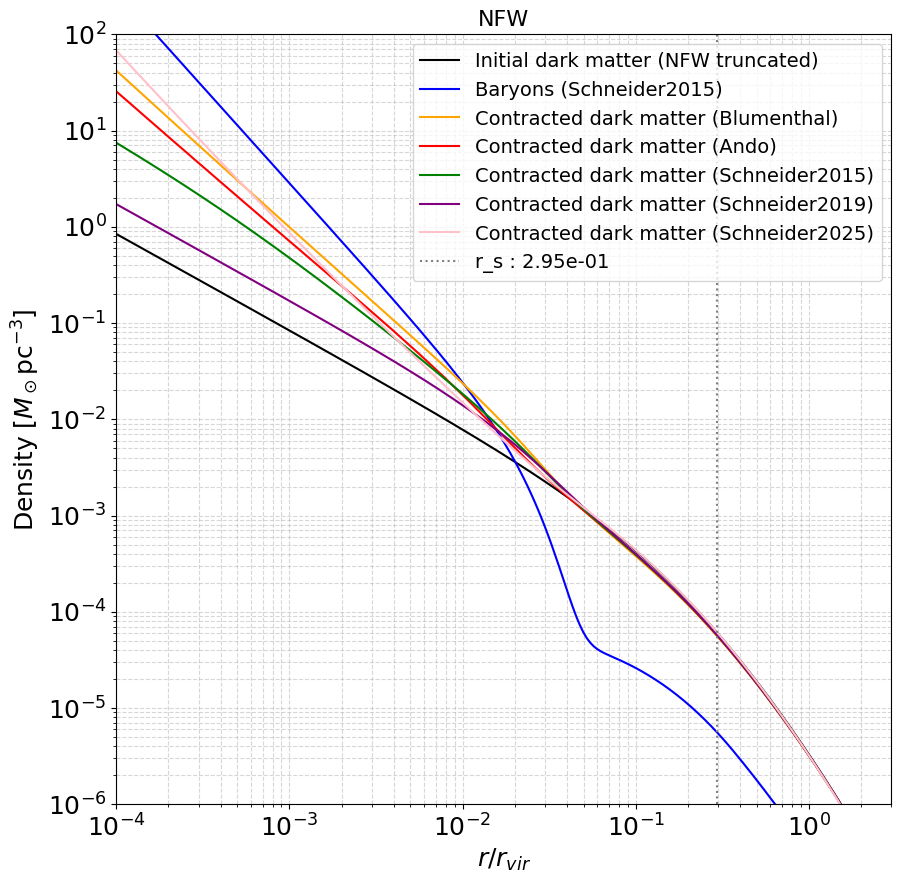

In [10]:
if config.DM_PROFILE == 'NFW' and config.BARYON_PROFILE in schneider_profiles and config.FORCE_TRUNCATED_NFW_FOR_SCHNEIDER:
    dm_label = f'Initial dark matter ({dm} truncated)'
else:
    dm_label = f'Initial dark matter ({dm})'

plt.figure(figsize=FIGSIZE)
plt.loglog(r_n, halo['rho_dm_initial'], label=dm_label, color='black')
plt.loglog(r_n, rho_baryons, label=f'Baryons ({bar})', color='blue')
plt.loglog(rf_n_blumenthal, Blumenthal['rho_dm_contracted'], label='Contracted dark matter (Blumenthal)', color='orange')
plt.loglog(rf_n_ando, Ando['rho_dm_contracted'], label='Contracted dark matter (Ando)', color='red')
plt.loglog(rf_n_schneider2015, Schneider2015['rho_dm_contracted'], label='Contracted dark matter (Schneider2015)', color='green')
plt.loglog(rf_n_schneider2019, Schneider2019['rho_dm_contracted'], label='Contracted dark matter (Schneider2019)', color='purple')
plt.loglog(rf_n_schneider2025, Schneider2025['rho_dm_contracted'], label='Contracted dark matter (Schneider2025)', color='pink')
plt.axvline(r_s, label=f'r_s : {r_s:.2e}', c='grey', ls=':')

plt.xlim(XLIM)
plt.ylim(YLIM)
plt.xlabel(r'$r / r_{vir}$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=18)
plt.title(f'{dm}', fontsize=16)
plt.legend(fontsize=14, loc ='upper right')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Stacking of all contractions with the detail of baryons

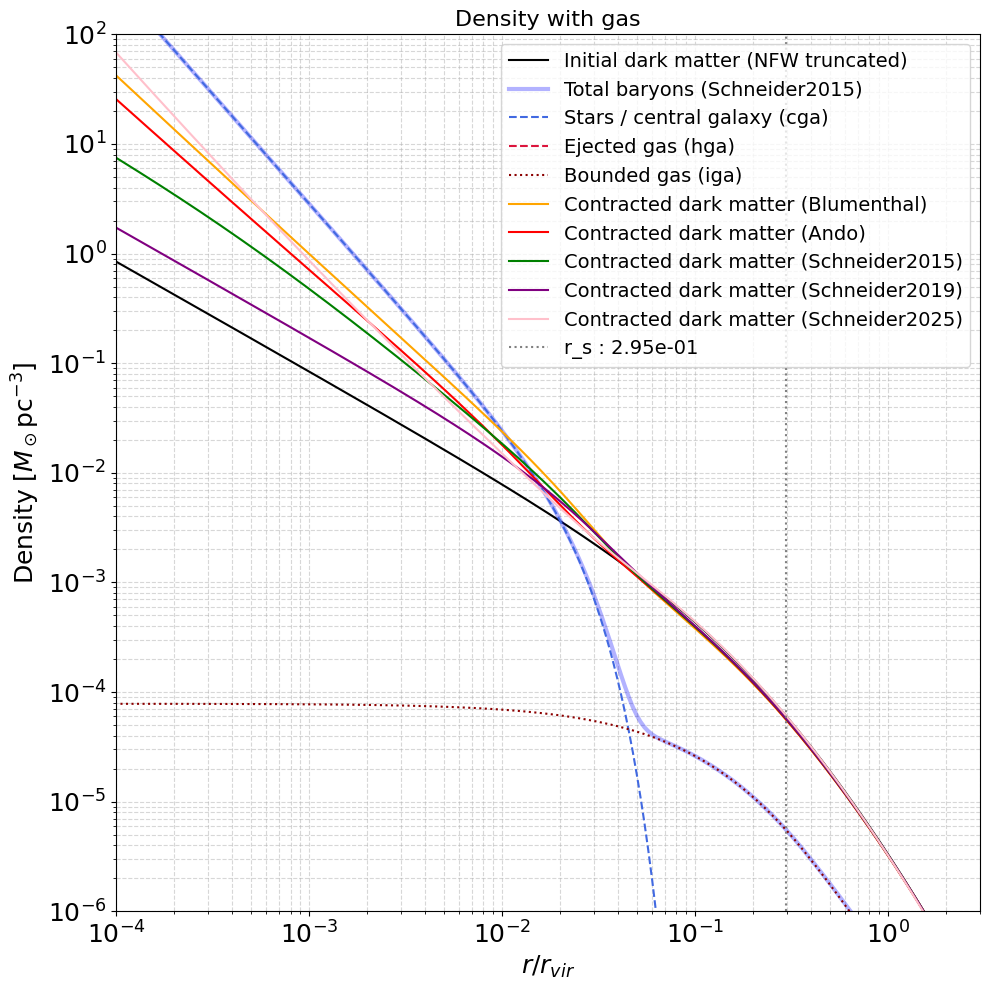

In [11]:
if config.DM_PROFILE == 'NFW' and config.BARYON_PROFILE in schneider_profiles and config.FORCE_TRUNCATED_NFW_FOR_SCHNEIDER:
    dm_label = f'Initial dark matter ({dm} truncated)'
else:
    dm_label = f'Initial dark matter ({dm})'

plt.figure(figsize=FIGSIZE)
plt.loglog(r_n, halo['rho_dm_initial'], label=dm_label, color='black')
plt.loglog(r_n, Schneider2015['rho_baryons'], label=f'Total baryons ({bar})', color='blue', linewidth=3, alpha=0.3)

if np.any(Schneider2015['rho_cga'] > 0):
    plt.loglog(r_n, Schneider2015['rho_cga'], label='Stars / central galaxy (cga)', linestyle='--', color='royalblue')
    
if np.any(Schneider2015['rho_sga'] > 0):
    plt.loglog(r_n, Schneider2015['rho_sga'], label='Satellite galaxies (sga)', linestyle=':', color='navy')
    
if np.any(Schneider2015['rho_hga'] > 0):
    plt.loglog(r_n, Schneider2015['rho_hga'], label='Ejected gas (hga)', linestyle='--', color='crimson')
    
if np.any(Schneider2015['rho_iga'] > 0):
    plt.loglog(r_n, Schneider2015['rho_iga'], label='Bounded gas (iga)', linestyle=':', color='darkred')


plt.loglog(rf_n_blumenthal, Blumenthal['rho_dm_contracted'], label='Contracted dark matter (Blumenthal)', color='orange')
plt.loglog(rf_n_ando, Ando['rho_dm_contracted'], label='Contracted dark matter (Ando)', color='red')
plt.loglog(rf_n_schneider2015, Schneider2015['rho_dm_contracted'] , label='Contracted dark matter (Schneider2015)', color='green')
plt.loglog(rf_n_schneider2019, Schneider2019['rho_dm_contracted'] , label='Contracted dark matter (Schneider2019)', color='purple')
plt.loglog(rf_n_schneider2025, Schneider2025['rho_dm_contracted'] , label='Contracted dark matter (Schneider2025)', color='pink')
plt.axvline(r_s, label =f'r_s : {r_s:.2e}', c='grey', ls=':')
plt.xlim(XLIM)
plt.ylim(YLIM)

title_text = "Density with gas" if config.GAS else "Density without gas"
plt.title(title_text, fontsize=16)

plt.xlabel(r'$r / r_{vir}$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=18)

plt.legend(fontsize=14, loc='upper right')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

Mass of the element during the contraction

In [12]:
contraction_models = ['Blumenthal', 'Ando', 'Schneider2015', 'Schneider2019', 'Schneider2025']
contracted_masses = {}

for model in contraction_models:
    config.CONTRACTION = model
    halo_data = general.contract_halo() 
    contracted_masses[model] = halo_data['mass_dm_contracted']

mass_dm = halo_data['mass_dm_initial']
mass_b = halo_data['mass_baryons']

Searching the intersection 

In [13]:
search_min = 1e-5
search_max = 2 * halo['r_vir']

intersections_dm_baryons = profiles.find_intersections(r_n, mass_dm, mass_b, x_min=search_min, x_max=search_max)

Intersection of the mass dark matter and the mass of baryons

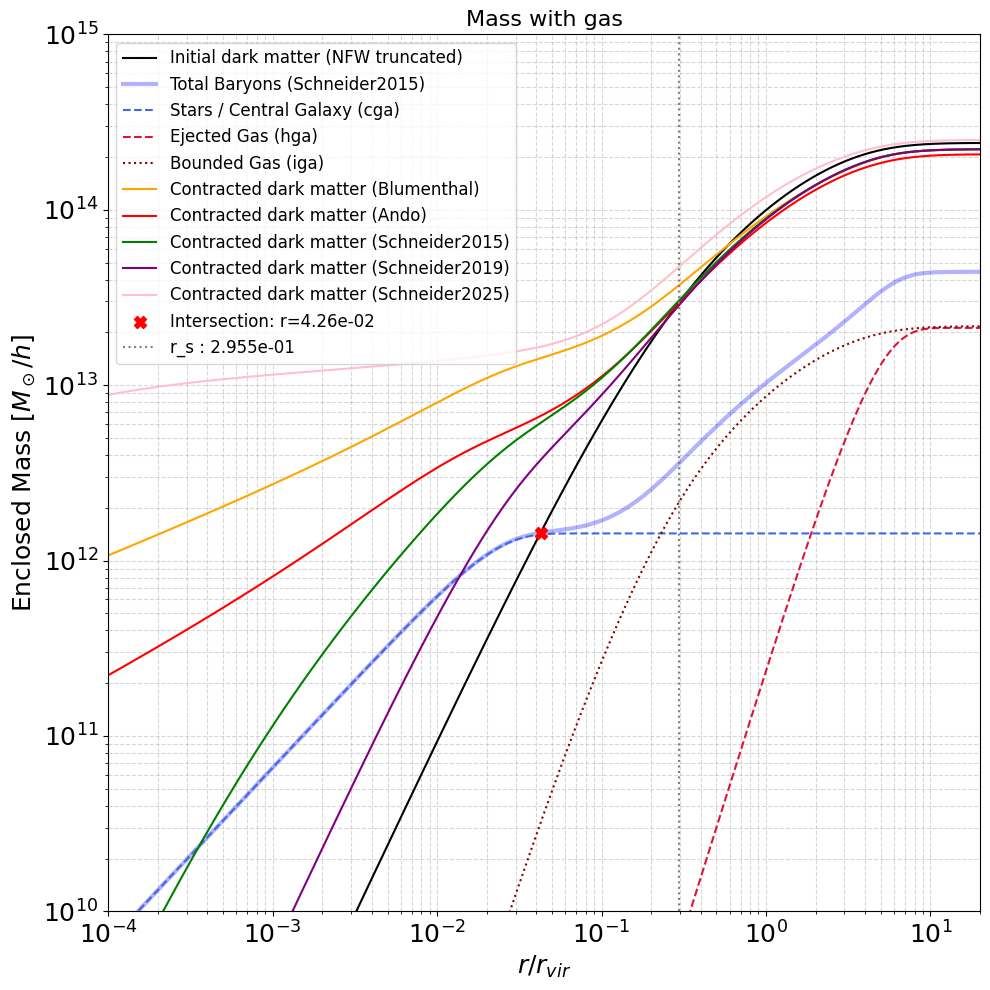

In [14]:
if config.DM_PROFILE == 'NFW' and config.BARYON_PROFILE in schneider_profiles and config.FORCE_TRUNCATED_NFW_FOR_SCHNEIDER:
    dm_label = f'Initial dark matter ({dm} truncated)'
else:
    dm_label = f'Initial dark matter ({dm})'

plt.figure(figsize=FIGSIZE)

plt.loglog(r_n, halo['mass_dm_initial'], label=dm_label, color='black')
plt.loglog(r_n, Schneider2015['mass_baryons'], label=f'Total Baryons ({bar})', color='blue', linewidth=3, alpha=0.3)

if np.any(Schneider2015['mass_cga'] > 0):
    plt.loglog(r_n, Schneider2015['mass_cga'], label='Stars / Central Galaxy (cga)', linestyle='--', color='royalblue')
    
if np.any(Schneider2015['mass_sga'] > 0):
    plt.loglog(r_n, Schneider2015['mass_sga'], label='Satellite Galaxies (sga)', linestyle=':', color='navy')
    
if np.any(Schneider2015['mass_hga'] > 0):
    plt.loglog(r_n, Schneider2015['mass_hga'], label='Ejected Gas (hga)', linestyle='--', color='crimson')
    
if np.any(Schneider2015['mass_iga'] > 0):
    plt.loglog(r_n, Schneider2015['mass_iga'], label='Bounded Gas (iga)', linestyle=':', color='darkred')

plt.loglog(rf_n_blumenthal, Blumenthal['mass_dm_contracted'], label='Contracted dark matter (Blumenthal)', color='orange')
plt.loglog(rf_n_ando, Ando['mass_dm_contracted'], label='Contracted dark matter (Ando)', color='red')
plt.loglog(rf_n_schneider2015, Schneider2015['mass_dm_contracted'] , label='Contracted dark matter (Schneider2015)', color='green')
plt.loglog(rf_n_schneider2019, Schneider2019['mass_dm_contracted'] , label='Contracted dark matter (Schneider2019)', color='purple')
plt.loglog(rf_n_schneider2025, Schneider2025['mass_dm_contracted'] , label='Contracted dark matter (Schneider2025)', color='pink')

for (x_int, y_int) in intersections_dm_baryons:
    plt.scatter(x_int, y_int, color='red', s=75, zorder=10, marker='X', label=f'Intersection: r={x_int:.2e}')
plt.axvline(r_s, label=f'r_s : {r_s:.3e}', c='grey', ls=':')

plt.xlim(1e-4,2e1)
plt.ylim(1e10,1e15) 

plt.xlabel(r'$r / r_{vir}$', fontsize=18)
plt.ylabel(r'Enclosed Mass [$M_\odot / h$]', fontsize=18)

title_text = "Mass with gas" if config.GAS else "Mass without gas"
plt.title(title_text, fontsize=16)

plt.legend(fontsize=12, loc='upper left') 
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

Ratio of the final radius over the initial one

In [15]:
ratio_blumenthal = rf_n_blumenthal / r_n
ratio_ando = rf_n_ando / r_n
ratio_schneider2015 = rf_n_schneider2015 / r_n
ratio_schneider2019 = rf_n_schneider2019 / r_n
ratio_schneider2025 = rf_n_schneider2025 / r_n

Stacking of the radii

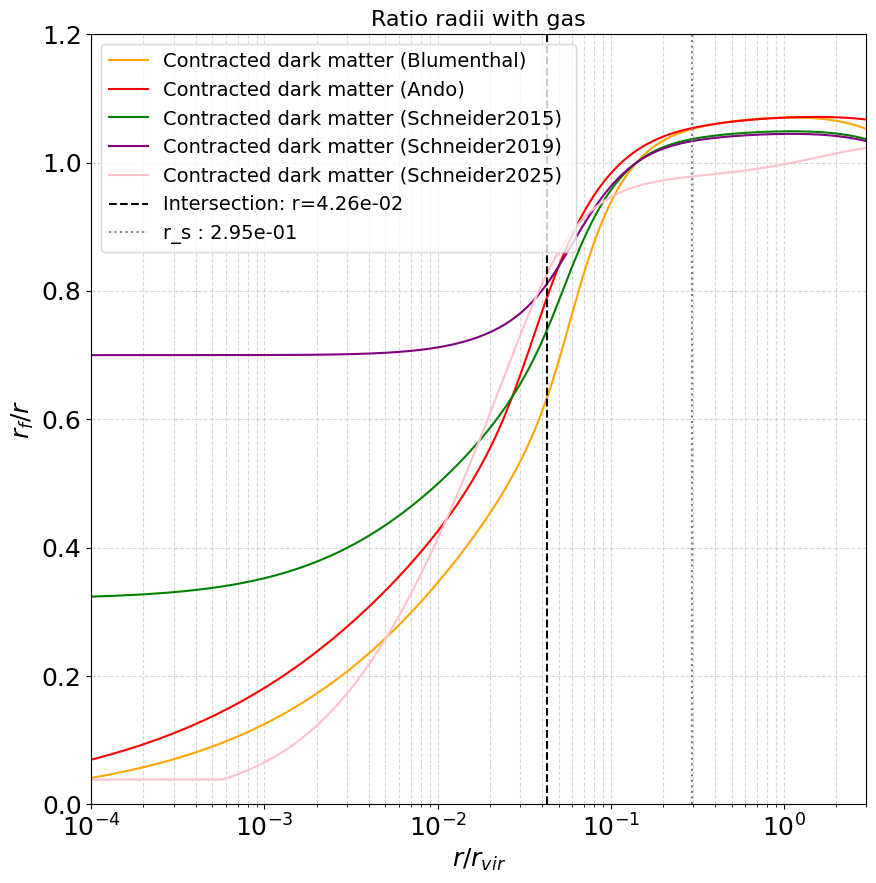

In [16]:
plt.figure(figsize=FIGSIZE)
plt.semilogx(r_n, ratio_blumenthal, label=f'Contracted dark matter (Blumenthal) ', color='orange')
plt.semilogx(r_n, ratio_ando, label=f'Contracted dark matter (Ando) ', color='red')
plt.semilogx(r_n, ratio_schneider2015 , label=f'Contracted dark matter (Schneider2015) ', color='green')
plt.semilogx(r_n, ratio_schneider2019 , label=f'Contracted dark matter (Schneider2019) ', color='purple')
plt.semilogx(r_n, ratio_schneider2025 , label=f'Contracted dark matter (Schneider2025) ', color='pink')

plt.axvline(x_int, label=f'Intersection: r={x_int:.2e}', c='black', ls='--')
plt.axvline(r_s, label=f'r_s : {r_s:.2e}', c='grey', ls=':')
plt.xlim(XLIM)
plt.ylim(0,1.2)

title_text = "Ratio radii with gas" if config.GAS else "Ratio radii without gas"
plt.title(title_text, fontsize=16)

plt.xlabel(r'$r / r_{vir}$', fontsize=18)
plt.ylabel(r'$r_f / r$', fontsize=18)
plt.legend(fontsize=14)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()